# 14 — Toronto multi-scenario accessibility × Bike Share linkage

## Purpose

Notebook 13 created scenario-specific thermal walking networks for all hot and
matched-reference thermal scenarios.

This notebook recomputes **heat-conditioned transit accessibility for every
scenario** using a constant analytical design:

- same 50 accessibility origins;
- same transit destinations;
- same 10-minute generalized walking budget;
- same λ = 0.05 reference impedance model;
- same walking-network topology.

It then links each scenario's spatial accessibility loss to **same-day Bike Share
station response** from Notebook 10.

This creates the stronger chain:

**weather scenario → UTCI → network impedance → accessibility loss → observed
Bike Share response**

The behavioral linkage remains observational and exploratory.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and project paths

In [9]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
import requests

from scipy.spatial import cKDTree
from scipy.stats import pearsonr, spearmanr

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_RAW = TORONTO_DATA / "raw"
TORONTO_INTERIM = TORONTO_DATA / "interim"
TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

ACCESSIBILITY_DIR = TORONTO_OUTPUTS / "accessibility"
NETWORK_DIR = TORONTO_INTERIM / "thermal_network_multiday"
NETWORK_OUTPUTS = TORONTO_OUTPUTS / "thermal_network_multiday"
PANEL_DIR = TORONTO_OUTPUTS / "bikeshare_panel"

OUTPUT_DIR = (
    TORONTO_OUTPUTS
    / "multiscenario_accessibility_bikeshare"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

ORIGINS_GPKG = (
    ACCESSIBILITY_DIR
    / "toronto_origin_accessibility_absolute_vs_relative_lambda_005.gpkg"
)

NETWORK_SUMMARY_PATH = (
    NETWORK_OUTPUTS
    / "toronto_multiday_thermal_network_summary.csv"
)

PANEL_PATH = (
    PANEL_DIR
    / "toronto_summer2025_station_day_panel.parquet"
)

print("Origins:", ORIGINS_GPKG)
print("Network summary:", NETWORK_SUMMARY_PATH)
print("Bike Share panel:", PANEL_PATH)

Origins: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/accessibility/toronto_origin_accessibility_absolute_vs_relative_lambda_005.gpkg
Network summary: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/thermal_network_multiday/toronto_multiday_thermal_network_summary.csv
Bike Share panel: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/bikeshare_panel/toronto_summer2025_station_day_panel.parquet


## 2. Accessibility parameters

In [10]:
GENERALIZED_BUDGET_S = 600.0
LAMBDA_REFERENCE = 0.05

NORMAL_WEIGHT = "walk_time_s"
THERMAL_WEIGHT = "thermal_cost_s"

K_STATION_INTERPOLATION = 5
EPSILON_M = 1.0

print(
    "Generalized walking budget:",
    GENERALIZED_BUDGET_S,
    "seconds",
)

Generalized walking budget: 600.0 seconds


## 3. Load the same accessibility origins used in Notebook 07

The spatial origins are reused directly to ensure comparability.

In [11]:
if not ORIGINS_GPKG.exists():
    raise FileNotFoundError(
        "Notebook 07 origin accessibility output is missing."
    )

origins = gpd.read_file(
    ORIGINS_GPKG
)

print(
    "Origins loaded:",
    len(origins),
)

print(
    "Origin CRS:",
    origins.crs,
)

display(
    origins.head()
)

Origins loaded: 50
Origin CRS: EPSG:32617


,origin,y,x,street_count,highway,railway,normal_access,absolute_access,relative_access,absolute_loss_pct,relative_loss_pct,geometry
0,8711032240,4.835186e+06,629837.061559,3,None,None,47,35,47,25.531915,0.0,POINT (629837.062 4835186.388)
1,55808328,4.835921e+06,629502.403934,3,None,None,63,38,63,39.682540,0.0,POINT (629502.404 4835921.194)
2,8961478493,4.834920e+06,628851.941061,3,None,None,25,21,25,16.000000,0.0,POINT (628851.941 4834919.558)
3,14277092032,4.836497e+06,628534.028795,1,None,None,22,13,22,40.909091,0.0,POINT (628534.029 4836496.779)
4,2143402269,4.835457e+06,629198.275433,3,None,None,45,30,45,33.333333,0.0,POINT (629198.275 4835456.861)


## 4. Load thermal-network scenario summary

In [12]:
if not NETWORK_SUMMARY_PATH.exists():
    raise FileNotFoundError(
        "Notebook 13 network summary is missing."
    )

scenarios = pd.read_csv(
    NETWORK_SUMMARY_PATH
)

scenarios["date"] = pd.to_datetime(
    scenarios["date"]
)

scenarios = (
    scenarios
    .sort_values("date")
    .reset_index(drop=True)
)

print(
    "Scenarios:",
    len(scenarios),
)

display(
    scenarios[
        [
            "scenario_id",
            "scenario_role",
            "date",
            "mean_cost_ratio_lambda_005",
            "share_network_length_above_32C",
            "graphml",
        ]
    ]
)

Scenarios: 14


,scenario_id,scenario_role,date,mean_cost_ratio_lambda_005,share_network_length_above_32C,graphml
0,reference_2025-06-16_1500,reference,2025-06-16,1.006348,0.702757,/scratch/project_2010417/paper3/heat-condition...
1,hot_2025-06-22_1500,hot,2025-06-22,1.385924,1.000000,/scratch/project_2010417/paper3/heat-condition...
2,hot_2025-06-23_1500,hot,2025-06-23,1.408544,1.000000,/scratch/project_2010417/paper3/heat-condition...
3,hot_2025-06-24_1500,hot,2025-06-24,1.398404,1.000000,/scratch/project_2010417/paper3/heat-condition...
4,reference_2025-06-29_1500,reference,2025-06-29,1.000000,0.000000,/scratch/project_2010417/paper3/heat-condition...
5,reference_2025-07-03_1500,reference,2025-07-03,1.000000,0.000000,/scratch/project_2010417/paper3/heat-condition...
6,hot_2025-07-06_1500,hot,2025-07-06,1.172020,0.995840,/scratch/project_2010417/paper3/heat-condition...
7,reference_2025-07-08_1500,reference,2025-07-08,1.000000,0.000000,/scratch/project_2010417/paper3/heat-condition...
8,reference_2025-07-20_1500,reference,2025-07-20,1.000000,0.000000,/scratch/project_2010417/paper3/heat-condition...
9,hot_2025-07-24_1500,hot,2025-07-24,1.189955,0.997965,/scratch/project_2010417/paper3/heat-condition...


## 5. Load first thermal graph and establish common network CRS

In [13]:
first_graph_path = Path(
    scenarios.iloc[0][
        "graphml"
    ]
)

if not first_graph_path.exists():
    raise FileNotFoundError(
        first_graph_path
    )

G_first = ox.load_graphml(
    first_graph_path
)

first_nodes, first_edges = (
    ox.graph_to_gdfs(
        G_first,
        nodes=True,
        edges=True,
        fill_edge_geometry=True,
    )
)

NETWORK_CRS = first_nodes.crs

print("Network CRS:", NETWORK_CRS)
print("Nodes:", len(first_nodes))
print("Edges:", len(first_edges))

Network CRS: EPSG:32617
Nodes: 3984
Edges: 10682


## 6. Snap the Notebook 07 origins to the fixed network topology

In [14]:
origins_network = origins.to_crs(
    NETWORK_CRS
).copy()

origins_network[
    "origin_id"
] = np.arange(
    len(origins_network)
)

origins_network[
    "origin_node"
] = ox.distance.nearest_nodes(
    G_first,
    X=origins_network.geometry.x,
    Y=origins_network.geometry.y,
)

print(
    "Unique snapped origin nodes:",
    origins_network[
        "origin_node"
    ].nunique(),
)

Unique snapped origin nodes: 50


## 7. Query transit-stop destinations once

Transit destinations are held constant across all scenarios.

We use OpenStreetMap bus stops and public-transport stop/platform features
within the thermal-network footprint, then snap them to the same network.

In [15]:
import time
import osmnx as ox

transit_tags = {
    "highway": "bus_stop",
    "public_transport": [
        "platform",
        "stop_position",
    ],
}

max_attempts = 5
wait_seconds = 15

transit_raw = None

for attempt in range(1, max_attempts + 1):

    try:

        print(
            f"Overpass attempt {attempt}/{max_attempts}"
        )

        transit_raw = ox.features_from_polygon(
            network_polygon_wgs84,
            tags=transit_tags,
        )

        print(
            "✓ Transit data retrieved"
        )

        break

    except Exception as exc:

        print(
            "Query failed:",
            exc,
        )

        if attempt == max_attempts:
            raise

        print(
            f"Retrying after {wait_seconds} seconds..."
        )

        time.sleep(
            wait_seconds
        )

        wait_seconds *= 2

Overpass attempt 1/5
✓ Transit data retrieved


In [16]:
TRANSIT_CACHE = (
    TORONTO_INTERIM
    / "accessibility"
    / "uoft_transit_stops.gpkg"
)

if TRANSIT_CACHE.exists():

    print(
        "Using cached transit stops."
    )

    transit_raw = gpd.read_file(
        TRANSIT_CACHE
    )

else:

    import time

    transit_tags = {
        "highway": "bus_stop",
        "public_transport": [
            "platform",
            "stop_position",
        ],
    }

    max_attempts = 5
    wait_seconds = 15

    for attempt in range(
        1,
        max_attempts + 1,
    ):

        try:

            print(
                f"Overpass attempt "
                f"{attempt}/{max_attempts}"
            )

            transit_raw = (
                ox.features_from_polygon(
                    network_polygon_wgs84,
                    tags=transit_tags,
                )
            )

            break

        except Exception:

            if attempt == max_attempts:
                raise

            time.sleep(
                wait_seconds
            )

            wait_seconds *= 2

    TRANSIT_CACHE.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    transit_raw.to_file(
        TRANSIT_CACHE,
        driver="GPKG",
    )

    print(
        "Saved transit cache:",
        TRANSIT_CACHE
    )

Overpass attempt 1/5
Saved transit cache: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/accessibility/uoft_transit_stops.gpkg


## 8. Accessibility helper

Accessibility is the count of unique snapped transit-stop nodes reachable
within the 600-second generalized walking budget.

In [18]:
import time
import geopandas as gpd
import osmnx as ox


TRANSIT_CACHE = (
    TORONTO_INTERIM
    / "accessibility"
    / "uoft_transit_stops.gpkg"
)

TRANSIT_CACHE.parent.mkdir(
    parents=True,
    exist_ok=True,
)


# --------------------------------------------------
# Load cached transit stops if available
# --------------------------------------------------

if TRANSIT_CACHE.exists():

    print(
        "Using cached transit stops:"
    )

    print(
        TRANSIT_CACHE
    )

    transit_raw = gpd.read_file(
        TRANSIT_CACHE
    )


# --------------------------------------------------
# Otherwise retrieve from Overpass
# --------------------------------------------------

else:

    network_polygon = (
        first_edges
        .geometry
        .union_all()
        .convex_hull
    )

    network_polygon_wgs84 = (
        gpd.GeoSeries(
            [network_polygon],
            crs=NETWORK_CRS,
        )
        .to_crs(4326)
        .iloc[0]
    )

    transit_tags = {
        "highway": "bus_stop",
        "public_transport": [
            "platform",
            "stop_position",
        ],
    }

    transit_raw = None

    wait_seconds = 15

    for attempt in range(
        1,
        6,
    ):

        try:

            print(
                f"Overpass attempt {attempt}/5"
            )

            transit_raw = (
                ox.features_from_polygon(
                    network_polygon_wgs84,
                    tags=transit_tags,
                )
            )

            break

        except Exception as exc:

            print(
                "Overpass failed:",
                type(exc).__name__,
            )

            if attempt == 5:
                raise

            print(
                f"Retrying in {wait_seconds}s"
            )

            time.sleep(
                wait_seconds
            )

            wait_seconds *= 2

    if transit_raw is None:
        raise RuntimeError(
            "Transit data could not be retrieved."
        )

    transit_raw.to_file(
        TRANSIT_CACHE,
        driver="GPKG",
    )

    print(
        "Saved transit cache:",
        TRANSIT_CACHE,
    )


# --------------------------------------------------
# Clean and project
# --------------------------------------------------

if transit_raw.empty:

    raise RuntimeError(
        "Transit-stop dataset is empty."
    )


transit = transit_raw[
    transit_raw.geometry.notna()
].copy()


if transit.crs != NETWORK_CRS:

    transit = transit.to_crs(
        NETWORK_CRS
    )


# Convert polygons/lines to representative point
transit[
    "geometry"
] = transit.geometry.centroid


# --------------------------------------------------
# Snap stops to walking network
# --------------------------------------------------

transit[
    "stop_node"
] = ox.distance.nearest_nodes(
    G_first,
    X=transit.geometry.x,
    Y=transit.geometry.y,
)


transit_nodes = sorted(
    set(
        transit[
            "stop_node"
        ]
    )
)


# --------------------------------------------------
# Diagnostics
# --------------------------------------------------

print(
    "Transit features:",
    len(transit),
)

print(
    "Unique snapped transit nodes:",
    len(transit_nodes),
)

print(
    "First snapped nodes:",
    transit_nodes[:10],
)

Using cached transit stops:
/scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/accessibility/uoft_transit_stops.gpkg
Transit features: 223
Unique snapped transit nodes: 167
First snapped nodes: [42606791, 87858895, 332338922, 387491116, 387491118, 389677924, 389677953, 389677994, 389678007, 389678058]


## 9. Calculate normal baseline accessibility once

Because walking topology and walking time are fixed, the normal accessibility
baseline is common to every scenario.

In [22]:
transit_node_set = set(
    transit_nodes
)

def reachable_stop_count(
    graph,
    origin_node,
    weight,
    cutoff=GENERALIZED_BUDGET_S,
):
    lengths = nx.single_source_dijkstra_path_length(
        graph,
        source=origin_node,
        cutoff=cutoff,
        weight=weight,
    )

    return len(
        transit_node_set.intersection(
            lengths.keys()
        )
    )

print(
    "Helper ready."
)

print(
    "Transit destination nodes:",
    len(transit_node_set),
)

Helper ready.
Transit destination nodes: 167


In [23]:
# Convert GraphML edge attributes back to numeric
numeric_edge_fields = [
    "length",
    "walk_time_s",
    "thermal_cost_s",
    "utci_1500",
    "heat_excess",
    "cost_ratio",
]

for u, v, k, data in G_first.edges(
    keys=True,
    data=True,
):

    for field in numeric_edge_fields:

        if field in data:

            try:
                data[field] = float(
                    data[field]
                )
            except (
                TypeError,
                ValueError,
            ):
                pass

print(
    "Numeric edge attributes converted."
)

# Quick check
sample_edge = next(
    iter(
        G_first.edges(
            keys=True,
            data=True,
        )
    )
)

print(
    "Sample walk_time_s:",
    sample_edge[3].get(
        "walk_time_s"
    ),
    type(
        sample_edge[3].get(
            "walk_time_s"
        )
    ),
)

Numeric edge attributes converted.
Sample walk_time_s: 9.64903862382316 <class 'float'>


In [24]:
baseline_rows = []

for _, origin in origins_network.iterrows():

    origin_node = origin[
        "origin_node"
    ]

    count = reachable_stop_count(
        G_first,
        origin_node,
        NORMAL_WEIGHT,
    )

    baseline_rows.append(
        {
            "origin_id": int(
                origin[
                    "origin_id"
                ]
            ),
            "origin_node": origin_node,
            "normal_accessibility": int(
                count
            ),
        }
    )

baseline = pd.DataFrame(
    baseline_rows
)

print(
    "Mean normal reachable stops:",
    round(
        baseline[
            "normal_accessibility"
        ].mean(),
        2,
    ),
)

Mean normal reachable stops: 41.56


## 10. Recompute heat-conditioned accessibility for every scenario

In [25]:
scenario_origin_rows = []
scenario_summary_rows = []

for i, scenario in scenarios.iterrows():

    scenario_id = str(
        scenario[
            "scenario_id"
        ]
    )

    scenario_role = str(
        scenario[
            "scenario_role"
        ]
    )

    scenario_date = pd.Timestamp(
        scenario[
            "date"
        ]
    )

    graph_path = Path(
        scenario[
            "graphml"
        ]
    )

    print()
    print(
        "=" * 72
    )

    print(
        f"[{i + 1}/{len(scenarios)}] "
        f"{scenario_id}"
    )

    G_scenario = ox.load_graphml(
        graph_path
    )

    # GraphML attributes may return as strings.
    for u, v, k, data in G_scenario.edges(
        keys=True,
        data=True,
    ):

        for col in [
            "walk_time_s",
            "thermal_cost_s",
            "utci_1500",
            "heat_excess",
            "cost_ratio",
        ]:

            if col in data:

                try:
                    data[col] = float(
                        data[col]
                    )
                except Exception:
                    pass

    origin_results = []

    for _, origin in origins_network.iterrows():

        origin_id = int(
            origin[
                "origin_id"
            ]
        )

        origin_node = origin[
            "origin_node"
        ]

        normal_count = int(
            baseline.loc[
                baseline[
                    "origin_id"
                ] == origin_id,
                "normal_accessibility",
            ].iloc[0]
        )

        thermal_count = reachable_stop_count(
            G_scenario,
            origin_node,
            THERMAL_WEIGHT,
        )

        if normal_count > 0:

            accessibility_loss_pct = (
                (
                    normal_count
                    - thermal_count
                )
                / normal_count
                * 100
            )

        else:

            accessibility_loss_pct = np.nan

        origin_results.append(
            {
                "scenario_id": scenario_id,
                "scenario_role": scenario_role,
                "date": scenario_date,
                "origin_id": origin_id,
                "origin_node": origin_node,
                "normal_accessibility": normal_count,
                "thermal_accessibility": int(
                    thermal_count
                ),
                "accessibility_loss_pct": float(
                    accessibility_loss_pct
                ),
            }
        )

    scenario_origin_df = pd.DataFrame(
        origin_results
    )

    scenario_origin_rows.extend(
        origin_results
    )

    scenario_summary_rows.append(
        {
            "scenario_id": scenario_id,
            "scenario_role": scenario_role,
            "date": scenario_date,
            "mean_normal_accessibility": float(
                scenario_origin_df[
                    "normal_accessibility"
                ].mean()
            ),
            "mean_thermal_accessibility": float(
                scenario_origin_df[
                    "thermal_accessibility"
                ].mean()
            ),
            "mean_accessibility_loss_pct": float(
                scenario_origin_df[
                    "accessibility_loss_pct"
                ].mean()
            ),
            "median_accessibility_loss_pct": float(
                scenario_origin_df[
                    "accessibility_loss_pct"
                ].median()
            ),
            "sd_accessibility_loss_pct": float(
                scenario_origin_df[
                    "accessibility_loss_pct"
                ].std()
            ),
        }
    )

    print(
        "Mean thermal reachable stops:",
        round(
            scenario_origin_df[
                "thermal_accessibility"
            ].mean(),
            2,
        ),
    )

    print(
        "Mean accessibility loss:",
        round(
            scenario_origin_df[
                "accessibility_loss_pct"
            ].mean(),
            2,
        ),
        "%",
    )


[1/14] reference_2025-06-16_1500
Mean thermal reachable stops: 41.22
Mean accessibility loss: 0.79 %

[2/14] hot_2025-06-22_1500
Mean thermal reachable stops: 23.06
Mean accessibility loss: 43.76 %

[3/14] hot_2025-06-23_1500
Mean thermal reachable stops: 22.24
Mean accessibility loss: 45.53 %

[4/14] hot_2025-06-24_1500
Mean thermal reachable stops: 22.62
Mean accessibility loss: 44.77 %

[5/14] reference_2025-06-29_1500
Mean thermal reachable stops: 41.56
Mean accessibility loss: 0.0 %

[6/14] reference_2025-07-03_1500
Mean thermal reachable stops: 41.56
Mean accessibility loss: 0.0 %

[7/14] hot_2025-07-06_1500
Mean thermal reachable stops: 31.04
Mean accessibility loss: 24.79 %

[8/14] reference_2025-07-08_1500
Mean thermal reachable stops: 41.56
Mean accessibility loss: 0.0 %

[9/14] reference_2025-07-20_1500
Mean thermal reachable stops: 41.56
Mean accessibility loss: 0.0 %

[10/14] hot_2025-07-24_1500
Mean thermal reachable stops: 30.38
Mean accessibility loss: 26.38 %

[11/14]

## 11. Save origin-level multi-scenario accessibility

In [26]:
origin_panel = pd.DataFrame(
    scenario_origin_rows
)

scenario_accessibility = pd.DataFrame(
    scenario_summary_rows
)

ORIGIN_PANEL_PATH = (
    OUTPUT_DIR
    / "toronto_multiscenario_origin_accessibility.csv"
)

SCENARIO_ACCESS_PATH = (
    OUTPUT_DIR
    / "toronto_multiscenario_accessibility_summary.csv"
)

origin_panel.to_csv(
    ORIGIN_PANEL_PATH,
    index=False,
)

scenario_accessibility.to_csv(
    SCENARIO_ACCESS_PATH,
    index=False,
)

display(
    scenario_accessibility
    .sort_values(
        "mean_accessibility_loss_pct",
        ascending=False,
    )
)

,scenario_id,scenario_role,date,mean_normal_accessibility,mean_thermal_accessibility,mean_accessibility_loss_pct,median_accessibility_loss_pct,sd_accessibility_loss_pct
2,hot_2025-06-23_1500,hot,2025-06-23,41.56,22.24,45.527549,45.080645,11.804841
3,hot_2025-06-24_1500,hot,2025-06-24,41.56,22.62,44.770200,44.722222,11.341187
1,hot_2025-06-22_1500,hot,2025-06-22,41.56,23.06,43.755008,43.437244,11.278641
11,hot_2025-07-27_1500,hot,2025-07-27,41.56,26.94,34.747559,32.916667,10.688656
9,hot_2025-07-24_1500,hot,2025-07-24,41.56,30.38,26.378364,26.138716,9.483116
10,hot_2025-07-25_1500,hot,2025-07-25,41.56,30.74,25.539035,25.806452,9.244407
6,hot_2025-07-06_1500,hot,2025-07-06,41.56,31.04,24.785183,25.198413,9.410908
12,reference_2025-08-15_1500,reference,2025-08-15,41.56,36.86,11.744138,10.647773,7.102317
0,reference_2025-06-16_1500,reference,2025-06-16,41.56,41.22,0.789758,0.000000,1.377294
4,reference_2025-06-29_1500,reference,2025-06-29,41.56,41.56,0.000000,0.000000,0.000000


## 12. Compare hot and reference accessibility

In [27]:
accessibility_role_summary = (
    scenario_accessibility
    .groupby(
        "scenario_role"
    )
    .agg(
        scenarios=(
            "scenario_id",
            "count",
        ),
        mean_accessibility_loss_pct=(
            "mean_accessibility_loss_pct",
            "mean",
        ),
        mean_thermal_accessibility=(
            "mean_thermal_accessibility",
            "mean",
        ),
    )
    .reset_index()
)

display(
    accessibility_role_summary
)

,scenario_role,scenarios,mean_accessibility_loss_pct,mean_thermal_accessibility
0,hot,7,35.071842,26.717143
1,reference,7,1.790557,40.840000


## 13. Plot scenario-specific accessibility loss

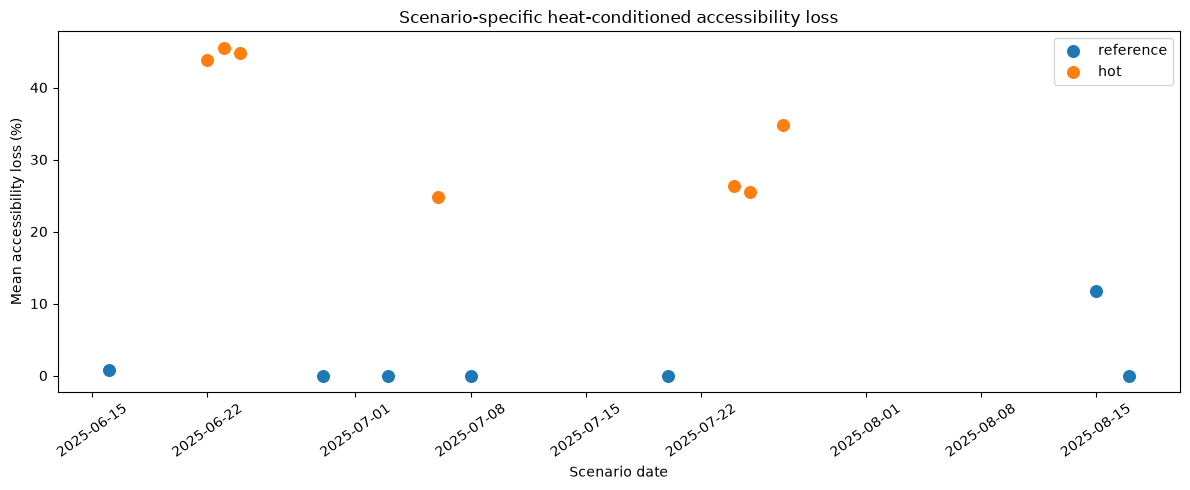

In [28]:
fig, ax = plt.subplots(
    figsize=(12, 5)
)

for role in [
    "reference",
    "hot",
]:

    subset = (
        scenario_accessibility[
            scenario_accessibility[
                "scenario_role"
            ] == role
        ]
        .sort_values("date")
    )

    ax.scatter(
        subset[
            "date"
        ],
        subset[
            "mean_accessibility_loss_pct"
        ],
        s=70,
        label=role,
    )

ax.set_xlabel(
    "Scenario date"
)

ax.set_ylabel(
    "Mean accessibility loss (%)"
)

ax.set_title(
    "Scenario-specific heat-conditioned accessibility loss"
)

ax.legend()

plt.xticks(
    rotation=35
)

plt.tight_layout()
plt.show()

## 14. Load Notebook 10 Bike Share station-day panel

In [29]:
if not PANEL_PATH.exists():
    raise FileNotFoundError(
        "Notebook 10 Bike Share panel is missing."
    )

panel = pd.read_parquet(
    PANEL_PATH
)

panel["date"] = pd.to_datetime(
    panel["date"]
)

print(
    "Bike Share panel rows:",
    len(panel),
)

print(
    "Unique stations:",
    panel[
        "station_id_join"
    ].nunique(),
)

Bike Share panel rows: 6900
Unique stations: 75


## 15. Retrieve current Bike Share station coordinates

Current GBFS geometry is retained as the same spatial proxy used in the earlier
notebooks.

In [30]:
GBFS_ROOT_CANDIDATES = [
    (
        "https://tor.publicbikesystem.net/"
        "ube/gbfs/v1/gbfs.json"
    ),
    (
        "https://tor.publicbikesystem.net/"
        "customer/gbfs/v2/gbfs.json"
    ),
]

gbfs_root = None

for candidate in GBFS_ROOT_CANDIDATES:

    try:

        response = requests.get(
            candidate,
            timeout=30,
        )

        if response.ok:

            gbfs_root = response.json()
            break

    except Exception:
        pass

if gbfs_root is None:
    raise RuntimeError(
        "Toronto GBFS feed unavailable."
    )

data_section = gbfs_root.get(
    "data",
    {}
)

if "en" in data_section:

    feeds = (
        data_section[
            "en"
        ].get(
            "feeds",
            []
        )
    )

else:

    feeds = (
        data_section.get(
            "feeds",
            []
        )
    )

station_info_url = None

for feed in feeds:

    if feed.get(
        "name"
    ) == "station_information":

        station_info_url = feed.get(
            "url"
        )

        break

if station_info_url is None:
    raise RuntimeError(
        "station_information feed unavailable."
    )

station_json = requests.get(
    station_info_url,
    timeout=30,
).json()

station_df = pd.DataFrame(
    station_json[
        "data"
    ][
        "stations"
    ]
)

station_df[
    "station_id_join"
] = (
    station_df[
        "station_id"
    ]
    .astype(str)
    .str.strip()
)

stations = gpd.GeoDataFrame(
    station_df,
    geometry=gpd.points_from_xy(
        station_df[
            "lon"
        ],
        station_df[
            "lat"
        ],
    ),
    crs=4326,
).to_crs(
    NETWORK_CRS
)

## 16. Restrict to Bike Share stations near the accessibility origins

In [31]:
pilot_polygon = (
    origins_network
    .geometry
    .union_all()
    .convex_hull
    .buffer(150)
)

analysis_stations = stations[
    stations.geometry.within(
        pilot_polygon
    )
    |
    stations.geometry.touches(
        pilot_polygon
    )
].copy()

print(
    "Analysis stations:",
    len(
        analysis_stations
    ),
)

Analysis stations: 75


## 17. Interpolate scenario-specific accessibility loss to Bike Share stations

For each scenario, accessibility loss is interpolated from the five nearest
accessibility origins using inverse-distance weighting.

In [32]:
origin_xy = np.column_stack(
    [
        origins_network.geometry.x.to_numpy(),
        origins_network.geometry.y.to_numpy(),
    ]
)

station_xy = np.column_stack(
    [
        analysis_stations.geometry.x.to_numpy(),
        analysis_stations.geometry.y.to_numpy(),
    ]
)

tree = cKDTree(
    origin_xy
)

distances, indices = tree.query(
    station_xy,
    k=min(
        K_STATION_INTERPOLATION,
        len(origins_network),
    ),
)

if distances.ndim == 1:

    distances = distances[
        :,
        None,
    ]

    indices = indices[
        :,
        None,
    ]

weights = 1.0 / (
    distances
    + EPSILON_M
)

weights = (
    weights
    / weights.sum(
        axis=1,
        keepdims=True,
    )
)

station_accessibility_rows = []

origin_id_order = (
    origins_network[
        "origin_id"
    ]
    .to_numpy()
)

for scenario_id, group in origin_panel.groupby(
    "scenario_id"
):

    group_indexed = (
        group
        .set_index(
            "origin_id"
        )
        .reindex(
            origin_id_order
        )
    )

    loss_values = (
        group_indexed[
            "accessibility_loss_pct"
        ]
        .to_numpy(
            dtype=float
        )
    )

    station_loss = np.sum(
        weights
        * loss_values[
            indices
        ],
        axis=1,
    )

    scenario_role = str(
        group[
            "scenario_role"
        ].iloc[0]
    )

    scenario_date = pd.Timestamp(
        group[
            "date"
        ].iloc[0]
    )

    for station_idx, station_row in (
        analysis_stations
        .reset_index(drop=True)
        .iterrows()
    ):

        station_accessibility_rows.append(
            {
                "scenario_id": scenario_id,
                "scenario_role": scenario_role,
                "date": scenario_date,
                "station_id_join": str(
                    station_row[
                        "station_id_join"
                    ]
                ),
                "modeled_accessibility_loss_pct": float(
                    station_loss[
                        station_idx
                    ]
                ),
            }
        )

station_accessibility = pd.DataFrame(
    station_accessibility_rows
)

print(
    "Scenario-station accessibility rows:",
    len(
        station_accessibility
    ),
)

Scenario-station accessibility rows: 1050


## 18. Merge scenario-specific accessibility with same-day Bike Share response

In [33]:
response_columns = [
    "station_id_join",
    "date",
    "station_trips",
    "city_trips",
    "weekday_adjusted_response",
    "station_city_share",
    "log_station_city_share",
]

available_response_columns = [
    col
    for col in response_columns
    if col in panel.columns
]

panel_response = panel[
    available_response_columns
].copy()

panel_response[
    "station_id_join"
] = (
    panel_response[
        "station_id_join"
    ]
    .astype(str)
)

linked = station_accessibility.merge(
    panel_response,
    on=[
        "station_id_join",
        "date",
    ],
    how="left",
)

print(
    "Linked rows:",
    len(linked),
)

print(
    "Rows with Bike Share response:",
    linked[
        "weekday_adjusted_response"
    ].notna().sum(),
)

Linked rows: 1050
Rows with Bike Share response: 1050


## 19. Core multi-scenario behavioral association

In [34]:
valid = linked[
    [
        "modeled_accessibility_loss_pct",
        "weekday_adjusted_response",
    ]
].dropna()

if len(valid) >= 3:

    pearson_result = pearsonr(
        valid[
            "modeled_accessibility_loss_pct"
        ],
        valid[
            "weekday_adjusted_response"
        ],
    )

    spearman_result = spearmanr(
        valid[
            "modeled_accessibility_loss_pct"
        ],
        valid[
            "weekday_adjusted_response"
        ],
    )

    print(
        "Pearson r:",
        round(
            float(
                pearson_result.statistic
            ),
            4,
        ),
    )

    print(
        "Pearson p:",
        pearson_result.pvalue,
    )

    print(
        "Spearman rho:",
        round(
            float(
                spearman_result.statistic
            ),
            4,
        ),
    )

    print(
        "Spearman p:",
        spearman_result.pvalue,
    )

else:

    pearson_result = None
    spearman_result = None

    print(
        "Not enough linked observations."
    )

Pearson r: -0.0593
Pearson p: 0.05454595359495266
Spearman rho: -0.2077
Spearman p: 1.0649636720318392e-11


## 20. Hot and reference scenario associations separately

In [35]:
role_correlation_rows = []

for role in [
    "hot",
    "reference",
]:

    subset = linked[
        linked[
            "scenario_role"
        ] == role
    ][
        [
            "modeled_accessibility_loss_pct",
            "weekday_adjusted_response",
        ]
    ].dropna()

    if len(subset) >= 3:

        result = spearmanr(
            subset[
                "modeled_accessibility_loss_pct"
            ],
            subset[
                "weekday_adjusted_response"
            ],
        )

        role_correlation_rows.append(
            {
                "scenario_role": role,
                "n": len(subset),
                "spearman_rho": float(
                    result.statistic
                ),
                "p_value": float(
                    result.pvalue
                ),
            }
        )

role_correlations = pd.DataFrame(
    role_correlation_rows
)

display(
    role_correlations
)

,scenario_role,n,spearman_rho,p_value
0,hot,525,-0.064456,0.140241
1,reference,525,-0.037840,0.386888


## 21. Scenario-level accessibility versus aggregate Bike Share response

This collapses each scenario to one accessibility value and one mean station
response. With only 14 scenarios, this is descriptive rather than a strong
inferential test.

In [36]:
scenario_behavior = (
    linked
    .groupby(
        [
            "scenario_id",
            "scenario_role",
            "date",
        ]
    )
    .agg(
        mean_station_accessibility_loss_pct=(
            "modeled_accessibility_loss_pct",
            "mean",
        ),
        mean_bikeshare_response=(
            "weekday_adjusted_response",
            "mean",
        ),
        median_bikeshare_response=(
            "weekday_adjusted_response",
            "median",
        ),
        station_observations=(
            "station_id_join",
            "count",
        ),
    )
    .reset_index()
)

display(
    scenario_behavior
    .sort_values(
        "mean_station_accessibility_loss_pct",
        ascending=False,
    )
)

,scenario_id,scenario_role,date,mean_station_accessibility_loss_pct,mean_bikeshare_response,median_bikeshare_response,station_observations
1,hot_2025-06-23_1500,hot,2025-06-23,44.067426,-0.125108,-0.036160,75
2,hot_2025-06-24_1500,hot,2025-06-24,43.406244,-0.148795,-0.091082,75
0,hot_2025-06-22_1500,hot,2025-06-22,42.200348,-0.157743,-0.066971,75
6,hot_2025-07-27_1500,hot,2025-07-27,33.521968,0.037068,0.081484,75
4,hot_2025-07-24_1500,hot,2025-07-24,25.939117,-0.108421,-0.045566,75
5,hot_2025-07-25_1500,hot,2025-07-25,25.305444,-0.053637,0.000000,75
3,hot_2025-07-06_1500,hot,2025-07-06,24.631161,-0.155131,-0.054698,75
12,reference_2025-08-15_1500,reference,2025-08-15,11.038214,-0.055697,0.017842,75
7,reference_2025-06-16_1500,reference,2025-06-16,0.807845,-0.052186,0.007496,75
8,reference_2025-06-29_1500,reference,2025-06-29,0.000000,-0.104702,0.021128,75


## 22. Scatter: scenario-station accessibility loss vs Bike Share response

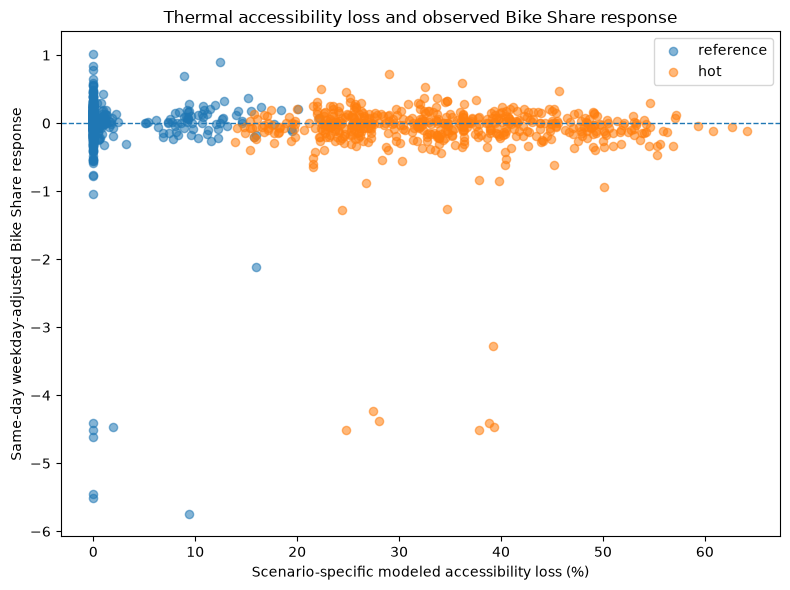

In [37]:
fig, ax = plt.subplots(
    figsize=(8, 6)
)

for role in [
    "reference",
    "hot",
]:

    subset = linked[
        linked[
            "scenario_role"
        ] == role
    ]

    ax.scatter(
        subset[
            "modeled_accessibility_loss_pct"
        ],
        subset[
            "weekday_adjusted_response"
        ],
        s=35,
        alpha=0.55,
        label=role,
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel(
    "Scenario-specific modeled accessibility loss (%)"
)

ax.set_ylabel(
    "Same-day weekday-adjusted Bike Share response"
)

ax.set_title(
    "Thermal accessibility loss and observed Bike Share response"
)

ax.legend()

plt.tight_layout()
plt.show()

## 23. High-loss versus low-loss station-day response

For each scenario, stations are split at that scenario's median modeled
accessibility loss.

In [38]:
linked[
    "loss_group"
] = (
    linked
    .groupby(
        "scenario_id"
    )[
        "modeled_accessibility_loss_pct"
    ]
    .transform(
        lambda x: np.where(
            x > x.median(),
            "higher_loss",
            "lower_loss",
        )
    )
)

loss_group_summary = (
    linked
    .groupby(
        [
            "scenario_role",
            "loss_group",
        ]
    )
    .agg(
        observations=(
            "station_id_join",
            "count",
        ),
        mean_accessibility_loss_pct=(
            "modeled_accessibility_loss_pct",
            "mean",
        ),
        mean_bikeshare_response=(
            "weekday_adjusted_response",
            "mean",
        ),
        median_bikeshare_response=(
            "weekday_adjusted_response",
            "median",
        ),
    )
    .reset_index()
)

display(
    loss_group_summary
)

,scenario_role,loss_group,observations,mean_accessibility_loss_pct,mean_bikeshare_response,median_bikeshare_response
0,hot,higher_loss,259,39.388615,-0.111449,-0.026940
1,hot,lower_loss,266,29.055363,-0.092170,-0.021345
2,reference,higher_loss,74,7.608128,-0.037496,0.033593
3,reference,lower_loss,451,0.721625,-0.034209,0.031042


## 24. Optional station fixed-effects regression

If `statsmodels` is available, estimate:

response_sd =
β₁ accessibility_loss_sd
+ station fixed effects
+ weekday fixed effects
+ error

This is still observational; station fixed effects only remove stable
between-station differences.

In [39]:
try:

    import statsmodels.formula.api as smf

    regression_df = linked[
        [
            "weekday_adjusted_response",
            "modeled_accessibility_loss_pct",
            "station_id_join",
            "date",
        ]
    ].dropna().copy()

    regression_df[
        "weekday"
    ] = (
        regression_df[
            "date"
        ]
        .dt.day_name()
    )

    regression_df[
        "loss_centered"
    ] = (
        regression_df[
            "modeled_accessibility_loss_pct"
        ]
        - regression_df[
            "modeled_accessibility_loss_pct"
        ].mean()
    )

    model = smf.ols(
        (
            "weekday_adjusted_response ~ "
            "loss_centered + "
            "C(station_id_join) + "
            "C(weekday)"
        ),
        data=regression_df,
    ).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": regression_df[
                "station_id_join"
            ]
        },
    )

    print(
        model.summary()
    )

except ImportError:

    model = None

    print(
        "statsmodels is not installed; "
        "fixed-effects diagnostic skipped."
    )

statsmodels is not installed; fixed-effects diagnostic skipped.


## 25. Save linked outputs

In [40]:
LINKED_PATH = (
    OUTPUT_DIR
    / "toronto_multiscenario_accessibility_bikeshare_station_panel.csv"
)

SCENARIO_BEHAVIOR_PATH = (
    OUTPUT_DIR
    / "toronto_multiscenario_accessibility_bikeshare_scenario_summary.csv"
)

LOSS_GROUP_PATH = (
    OUTPUT_DIR
    / "toronto_multiscenario_loss_group_summary.csv"
)

linked.to_csv(
    LINKED_PATH,
    index=False,
)

scenario_behavior.to_csv(
    SCENARIO_BEHAVIOR_PATH,
    index=False,
)

loss_group_summary.to_csv(
    LOSS_GROUP_PATH,
    index=False,
)

print("Saved:")
print("-", LINKED_PATH)
print("-", SCENARIO_BEHAVIOR_PATH)
print("-", LOSS_GROUP_PATH)

Saved:
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/multiscenario_accessibility_bikeshare/toronto_multiscenario_accessibility_bikeshare_station_panel.csv
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/multiscenario_accessibility_bikeshare/toronto_multiscenario_accessibility_bikeshare_scenario_summary.csv
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/multiscenario_accessibility_bikeshare/toronto_multiscenario_loss_group_summary.csv


## 26. Final diagnostics

In [41]:
print(
    "Thermal scenarios:",
    scenario_accessibility[
        "scenario_id"
    ].nunique(),
)

print(
    "Accessibility origins:",
    origin_panel[
        "origin_id"
    ].nunique(),
)

print(
    "Analysis Bike Share stations:",
    linked[
        "station_id_join"
    ].nunique(),
)

print(
    "Linked scenario-station observations:",
    linked[
        "weekday_adjusted_response"
    ].notna().sum(),
)

print()

print(
    "Mean accessibility loss range:",
    round(
        scenario_accessibility[
            "mean_accessibility_loss_pct"
        ].min(),
        2,
    ),
    "to",
    round(
        scenario_accessibility[
            "mean_accessibility_loss_pct"
        ].max(),
        2,
    ),
    "%",
)

if spearman_result is not None:

    print(
        "Overall accessibility-response Spearman:",
        round(
            float(
                spearman_result.statistic
            ),
            4,
        ),
    )

    print(
        "Overall accessibility-response p-value:",
        spearman_result.pvalue,
    )

Thermal scenarios: 14
Accessibility origins: 50
Analysis Bike Share stations: 75
Linked scenario-station observations: 1050

Mean accessibility loss range: 0.0 to 45.53 %
Overall accessibility-response Spearman: -0.2077
Overall accessibility-response p-value: 1.0649636720318392e-11


## Interpretation

This notebook is the first point in the Toronto workflow where the thermal
accessibility surface changes with the meteorological scenario itself.

Therefore, any relationship with Bike Share is now based on:

- scenario-specific weather;
- scenario-specific SOLWEIG UTCI;
- scenario-specific network impedance;
- scenario-specific accessibility loss;
- same-day observed Bike Share response.

That is substantially stronger than the original one-event comparison.

However, it still does **not** establish causality or calibrate λ.

Important remaining limitations include:

- current rather than historical Bike Share station coordinates;
- a limited number of detailed thermal scenarios;
- simplified weather controls;
- Bike Share users are not equivalent to pedestrians;
- accessibility loss is interpolated from 50 origins rather than calculated
  directly at every station.

If results are promising, the next notebook should focus on **robustness and
model comparison**, especially λ sensitivity, threshold sensitivity, and direct
station-origin accessibility.